In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    drop_last=True
)

100%|██████████| 9.91M/9.91M [00:04<00:00, 2.39MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 555kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.60MB/s]


In [6]:
images, labels = next(iter(train_loader))

print("Images shape", images.shape)
print("Labels shape", labels.shape)

print("Minimum:", images.min().item())
print("Maximum:", images.max().item())

Images shape torch.Size([128, 1, 28, 28])
Labels shape torch.Size([128])
Minimum: -1.0
Maximum: 1.0


In [10]:
class DCGANGenerator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()

        self.model = nn.Sequential(
            # [B, 100, 1, 1] -> [B, 256, 7, 7]
            nn.ConvTranspose2d(
                noise_dim, 256,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # [B, 256, 7, 7] -> [B, 128, 14, 14]
            nn.ConvTranspose2d(
                256, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # [B, 128, 14, 14] -> [B, 1, 28, 28]
            nn.ConvTranspose2d(
                128, 1,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.Tanh()
        )

    def forward(self, x):
        return self.model(x)

In [11]:
noise_dim = 100

generator = DCGANGenerator(noise_dim)

z = torch.randn(4, noise_dim, 1, 1)

fake_images = generator(z)

print("Noise shape:", z.shape)
print("Generated images shape:", fake_images.shape)

Noise shape: torch.Size([4, 100, 1, 1])
Generated images shape: torch.Size([4, 1, 28, 28])


In [12]:
class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(

            # [B, 1, 28, 28] -> [B, 64, 14, 14]
            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # [B, 64, 14, 14] -> [B, 128, 7, 7]
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # [B, 128, 7, 7] -> [B, 1, 1, 1]
            nn.Conv2d(
                128, 1,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            )
        )
    def forward(self, x):
        x = self.model(x)
        return x.view(-1, 1)

In [13]:
discriminator = DCGANDiscriminator()

real_images, _ = next(iter(train_loader))

noise = torch.randn(4, noise_dim, 1, 1)
fake_images = generator(noise)

real_output = discriminator(real_images[:4])
fake_output = discriminator(fake_images)

print("Real images:", real_images[:4].shape)
print("Fake images:", fake_images.shape)

print("Real output:", real_output.shape)
print("Fake output:", fake_output.shape)

Real images: torch.Size([4, 1, 28, 28])
Fake images: torch.Size([4, 1, 28, 28])
Real output: torch.Size([4, 1])
Fake output: torch.Size([4, 1])


In [17]:
def weights_init(m):

    classname = m.__class__.__name__

    if classname.find("Conv") != -1:

        nn.init.normal_(m.weight.data, 0.0, 0.02)

    elif classname.find("BatchNorm") != -1:

        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

In [18]:
generator.apply(weights_init)
discriminator.apply(weights_init)

DCGANDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kernel_size=(7, 7), stride=(1, 1), bias=False)
  )
)

In [19]:
criterion = nn.BCEWithLogitsLoss()

In [21]:
lr = 0.0002

beta1 = 0.5
beta2 = 0.999

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=lr,
    betas=(beta1, beta2)
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=lr,
    betas=(beta1, beta2)
)

In [22]:
real_label = 1.0
fake_label = 0.0

real_output = discriminator(real_images[:4])

real_targets = torch.full(
    (4, 1),
    real_label
)

real_loss = criterion(
    real_output,
    real_targets
)

print("Real output:", real_output.detach())
print("Real loss:", real_loss.item())

Real output: tensor([[1.8943],
        [4.5382],
        [0.5182],
        [1.0910]])
Real loss: 0.2268989384174347


In [25]:
num_epochs = 20

fixed_noise = torch.randn(16, noise_dim, 1, 1)

G_losses = []
D_losses = []

for epoch in range(num_epochs):

    G_epoch_loss = 0.0
    D_epoch_loss = 0.0

    for real_images, _ in train_loader:

        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, 1)
        fake_labels = torch.zeros(batch_size, 1)

        # -------------------------
        # Train Discriminator
        # -------------------------

        discriminator.zero_grad()

        real_output = discriminator(real_images)
        real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size, noise_dim, 1, 1)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion(fake_output, fake_labels)

        D_loss = real_loss + fake_loss

        D_loss.backward()
        optimizer_D.step()

        # -------------------------
        # Train Generator
        # -------------------------

        for param in discriminator.parameters():
            param.requires_grad_(False)

        generator.zero_grad()

        noise = torch.randn(batch_size, noise_dim, 1, 1)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images)

        G_loss = criterion(fake_output, real_labels)

        G_loss.backward()
        optimizer_G.step()

        for param in discriminator.parameters():
            param.requires_grad_(True)

        # Accumulate losses
        D_epoch_loss += D_loss.item()
        G_epoch_loss += G_loss.item()

    # Calculate average losses
    D_epoch_loss /= len(train_loader)
    G_epoch_loss /= len(train_loader)

    D_losses.append(D_epoch_loss)
    G_losses.append(G_epoch_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"D Loss: {D_epoch_loss:.4f} "
        f"G Loss: {G_epoch_loss:.4f}"
    )

Epoch [1/20] D Loss: 0.4202 G Loss: 3.4946
Epoch [2/20] D Loss: 0.3159 G Loss: 2.5002
Epoch [3/20] D Loss: 0.4472 G Loss: 2.3077
Epoch [4/20] D Loss: 0.4876 G Loss: 2.2430
Epoch [5/20] D Loss: 0.6394 G Loss: 1.9041
Epoch [6/20] D Loss: 0.5892 G Loss: 1.9409
Epoch [7/20] D Loss: 0.7483 G Loss: 1.7165
Epoch [8/20] D Loss: 0.7091 G Loss: 1.6828
Epoch [9/20] D Loss: 0.6757 G Loss: 1.7977
Epoch [10/20] D Loss: 0.6989 G Loss: 1.7751
Epoch [11/20] D Loss: 0.7012 G Loss: 1.7696
Epoch [12/20] D Loss: 0.7106 G Loss: 1.7871
Epoch [13/20] D Loss: 0.7315 G Loss: 1.7888
Epoch [14/20] D Loss: 0.7289 G Loss: 1.7548
Epoch [15/20] D Loss: 0.7270 G Loss: 1.7920
Epoch [16/20] D Loss: 0.7178 G Loss: 1.7901
Epoch [17/20] D Loss: 0.7371 G Loss: 1.7873
Epoch [18/20] D Loss: 0.7804 G Loss: 1.7483
Epoch [19/20] D Loss: 0.7366 G Loss: 1.7323
Epoch [20/20] D Loss: 0.7332 G Loss: 1.7972


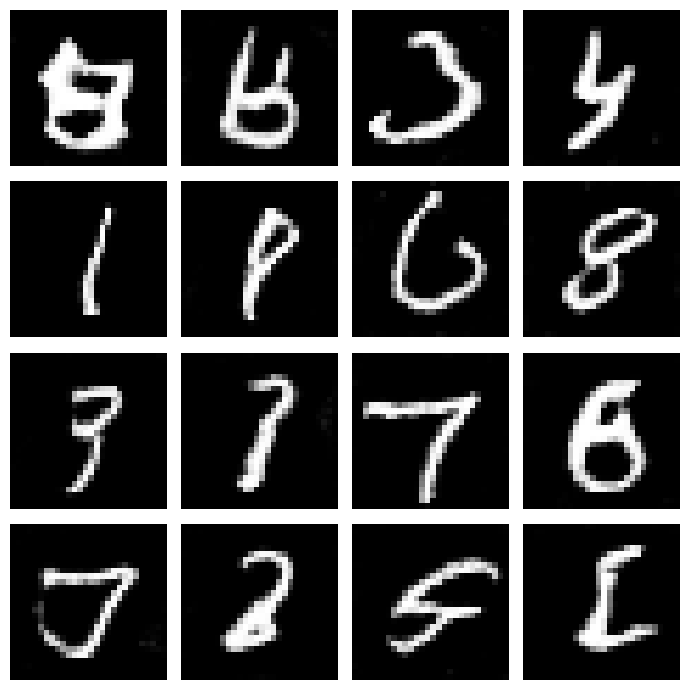

DCGANGenerator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Tanh()
  )
)

In [26]:
generator.eval()

with torch.no_grad():
    generated_images = generator(fixed_noise)

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for i, ax in enumerate(axes.flat):

    # Convert image range from [-1, 1] to [0, 1]
    image = generated_images[i].squeeze().cpu()
    image = (image + 1) / 2

    ax.imshow(image, cmap="gray")
    ax.axis("off")

plt.tight_layout()
plt.show()

generator.train()